# 营销策略稳健性与业务解释

本文件补充处理概率敏感性、S-learner 对照、客户画像、重新选择前 20% 的 bootstrap，以及五次开发集划分检查。

运行结果见下方代码输出及 `reports/audit/run_metadata.json`；所有结果表在运行时产生。原模型参数、20% 预算、Uplift − Response 主比较保持不变。新增分析均为探索性，不构成新的独立测试集确认。

使用原项目根目录作为工作目录，先完成 01–03。原测试集只用于客户划分完整性检查，不参与本文件模型拟合、预测或策略比较。

In [1]:
from pathlib import Path
import json, hashlib, platform, sys
from datetime import datetime, timezone
import numpy as np
import pandas as pd
import duckdb
import sklearn
import joblib
import matplotlib.pyplot as plt
from IPython.display import display, Markdown
from src.causal_robustness import (
    validate_splits, predict_response_models, propensity_sensitivity,
    slearner_comparison, customer_profiles, bootstrap_policies,
    repeated_split_stability
)

OUT = Path("reports/audit")
FIG = OUT / "figures"
OUT.mkdir(parents=True, exist_ok=True)
FIG.mkdir(parents=True, exist_ok=True)
required = ["data/processed/train.parquet", "data/processed/validation.parquet", "data/processed/test.parquet",
            "models/model_config.json", "models/policy_config.json", "models/response_model.joblib",
            "models/tlearner_m0.joblib", "models/tlearner_m1.joblib"]
missing = [p for p in required if not Path(p).exists()]
if missing:
    raise FileNotFoundError("请先在原项目根目录运行 01–03。缺少：" + ", ".join(missing))

BOOTSTRAP_REPEATS = 500
BOOTSTRAP_SEED = 20261113
SPLIT_SEEDS = (101, 202, 303, 404, 505)

def sha256(path):
    h = hashlib.sha256()
    with open(path, "rb") as f:
        for block in iter(lambda: f.read(1024*1024), b""):
            h.update(block)
    return h.hexdigest()

manifest = dict(status="running", started_utc=datetime.now(timezone.utc).isoformat(),
    python=sys.version, platform=platform.platform(), numpy=np.__version__, pandas=pd.__version__,
    sklearn=sklearn.__version__, duckdb=duckdb.__version__, joblib=joblib.__version__,
    bootstrap_repeats=BOOTSTRAP_REPEATS, bootstrap_seed=BOOTSTRAP_SEED,
    split_seeds=SPLIT_SEEDS, input_sha256={p: sha256(p) for p in required},
    scope="exploratory_development_analysis_original_test_not_evaluated")
source_paths = ["src/audit_core.py", "src/causal_robustness.py", "05_robustness_and_business.ipynb"]
def source_sha256(path):
    # Notebook outputs change during execution; hash only cell types and sources.
    if str(path).endswith(".ipynb"):
        notebook = json.loads(Path(path).read_text(encoding="utf-8"))
        source = [(c["cell_type"], "".join(c["source"])) for c in notebook["cells"]]
        return hashlib.sha256(json.dumps(source, ensure_ascii=False).encode("utf-8")).hexdigest()
    return sha256(path)

manifest["source_hash_scope"] = "Python file bytes; notebook cell types and sources excluding outputs"
manifest["source_sha256"] = {p: source_sha256(p) for p in source_paths}
(OUT / "run_metadata.json").write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8")

1806

In [2]:
with open("models/model_config.json", encoding="utf-8") as f:
    model_config = json.load(f)
with open("models/policy_config.json", encoding="utf-8") as f:
    policy_config = json.load(f)
assert policy_config["budget_share"] == .2, "本补充分析固定使用 20% 预算"
assert policy_config["primary_comparison"] == "Uplift - Response"
train_df = duckdb.read_parquet("data/processed/train.parquet").df()
valid_df = duckdb.read_parquet("data/processed/validation.parquet").df()
test_df = duckdb.read_parquet("data/processed/test.parquet").df()
validate_splits(train_df, valid_df, test_df)
models = {"response": joblib.load("models/response_model.joblib"),
          "m0": joblib.load("models/tlearner_m0.joblib"),
          "m1": joblib.load("models/tlearner_m1.joblib")}
evaluation = predict_response_models(valid_df, models, model_config)
print("训练客户：", len(train_df), "验证客户：", len(valid_df), "保留测试客户：", len(test_df))
print("本文件不对原测试集产生预测或新增策略结论。")

训练客户： 120023 验证客户： 40008 保留测试客户： 40008
本文件不对原测试集产生预测或新增策略结论。


## 1. 处理概率敏感性分析

比较 `e=0.5`、训练集实际处理比例、仅使用训练集拟合的逻辑回归 `e(X)`。固定模型、客户选择规则和预算；分别计算 DR 与 IPW。

逻辑回归仅使用处理前特征，不使用结果变量。预设将预测概率截断到 [0.01, 0.99]，报告截断比例及有效样本量。明显截断或极小有效样本量意味着重叠性需要进一步研究。AUC 接近 0.5、特征平衡或估计结果接近，均不能证明随机分配或无混杂。

下面的正态区间条件于已拟合的辅助模型，未加入估计处理概率本身的不确定性，不作为新的确认性检验。

,auc,brier,log_loss,min,p01,median,p99,max,clipped_fraction,clip_low,clip_high,training_treatment_share,treated_ess,control_ess
0,0.4996,0.25,0.6932,0.3977,0.4898,0.4993,0.5161,0.5744,0.0,0.01,0.99,0.4998,19994.4771,20008.2427


,comparison,extra_gain_per_1000,ci_low,ci_high,propensity_scenario,method
0,Uplift - Response,7.955,3.185,12.725,assumed_0.5,DR
1,Uplift - Response_p1,6.910,2.152,11.668,assumed_0.5,DR
2,Uplift - Random,4.350,0.712,7.987,assumed_0.5,DR
3,Uplift - RFM,7.925,3.097,12.753,assumed_0.5,DR
4,Uplift - Response,6.449,-3.927,16.824,assumed_0.5,IPW
5,Uplift - Response_p1,5.149,-5.187,15.485,assumed_0.5,IPW
6,Uplift - Random,1.349,-4.359,7.058,assumed_0.5,IPW
7,Uplift - RFM,5.499,-4.747,15.745,assumed_0.5,IPW
8,Uplift - Response,7.955,3.185,12.725,training_share,DR
9,Uplift - Response_p1,6.910,2.152,11.668,training_share,DR


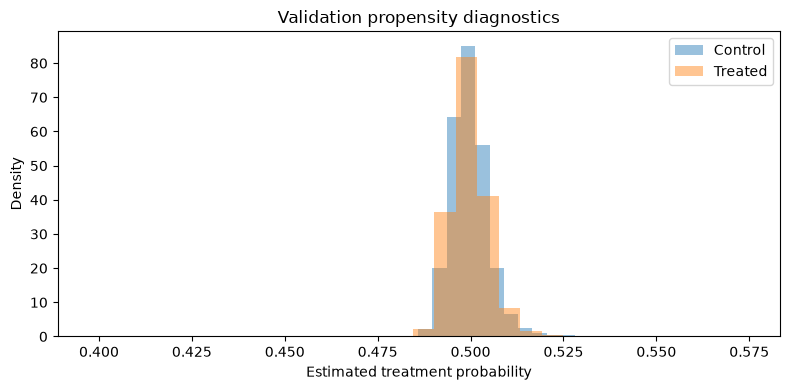

In [3]:
sensitivity_gains, sensitivity_differences, propensity_diagnostics, raw_propensity, propensity_model = propensity_sensitivity(
    train_df, evaluation, model_config, policy_config)
display(propensity_diagnostics.round(4))
display(sensitivity_differences.round(3))
sensitivity_gains.to_csv(OUT / "propensity_sensitivity_gains.csv", index=False)
sensitivity_differences.to_csv(OUT / "propensity_sensitivity_differences.csv", index=False)
propensity_diagnostics.to_csv(OUT / "propensity_diagnostics.csv", index=False)
Path("models/audit").mkdir(parents=True, exist_ok=True)
joblib.dump(propensity_model, "models/audit/propensity_logistic.joblib")
fig, ax = plt.subplots(figsize=(8, 4))
for treatment, label in [(0, "Control"), (1, "Treated")]:
    ax.hist(raw_propensity[evaluation.treatment_flg.eq(treatment)], bins=30, alpha=.45, density=True, label=label)
ax.set(xlabel="Estimated treatment probability", ylabel="Density", title="Validation propensity diagnostics")
ax.legend(); fig.tight_layout(); fig.savefig(FIG / "propensity_distribution.png", dpi=160); plt.show()

## 2. 一个额外的模型对照：S-learner

S-learner 使用相同的 HistGradientBoosting 分类器参数，把处理标记作为输入，分别设 T=1 和 T=0 生成差分分数。只在原训练集拟合，在原验证集评价。

所有排序规则共享原 T-learner 的结果回归预测作为 DR 辅助模型，并同时报告 IPW，避免更换排序规则时也更换评价口径。这里只检验一个预先指定的对照，不进行参数搜索，也不根据结果回头挑选主模型。

In [4]:
s_gains, s_differences, s_model = slearner_comparison(train_df, evaluation, model_config, policy_config)
display(s_gains.round(3))
display(s_differences.loc[s_differences.comparison.eq("Uplift - Slearner")].round(3))
s_gains.to_csv(OUT / "slearner_strategy_gains.csv", index=False)
s_differences.to_csv(OUT / "slearner_strategy_differences.csv", index=False)
joblib.dump(s_model, "models/audit/slearner.joblib")

,strategy,contacts_per_1000,gain_per_1000,ci_low,ci_high,method
0,Random,200.01,6.384,4.697,8.072,DR
1,RFM,200.01,2.809,0.232,5.386,DR
2,Response,200.01,2.779,0.408,5.149,DR
3,Response_p1,200.01,3.824,1.445,6.203,DR
4,Uplift,200.01,10.734,6.575,14.893,DR
5,Slearner,200.01,12.715,8.515,16.915,DR
6,Random,200.01,6.549,3.462,9.636,IPW
7,RFM,200.01,2.400,-5.910,10.709,IPW
8,Response,200.01,1.450,-6.951,9.850,IPW
9,Response_p1,200.01,2.749,-5.648,11.147,IPW


,comparison,extra_gain_per_1000,ci_low,ci_high,method
4,Uplift - Slearner,-1.981,-5.595,1.632,DR
9,Uplift - Slearner,-5.999,-11.627,-0.370,IPW


['models/audit/slearner.joblib']

## 3. 策略选中的客户画像与名单重合率

比较 Uplift、Response、Response_p1 和全体候选客户。数值变量报告均值、中位数和四分位数，性别报告类别占比。名单重合率的分母为每种策略选中人数；Jaccard 的分母为两个名单的并集。

这些是策略选择结果的描述，不表示年龄、消费或活跃度造成了营销效果差异。这里不输出包含客户 ID 的营销名单。

group,All,Response,Response_p1,Uplift
feature,,,,
age_clean,45.00,47.00,47.00,54.00
age_review_flag,0.00,0.00,0.00,0.00
avg_transaction_amount,395.60,309.94,309.13,316.40
recency_days,5.00,2.00,1.00,8.00
spend_30d,1794.29,4057.08,4022.47,805.42
spend_history,6105.00,13187.12,13061.99,3035.77
txn_count_30d,5.00,12.00,12.00,3.00
txn_count_history,15.00,40.00,40.00,9.00


,group,gender,count,proportion
0,All,F,14715,0.368
1,All,M,6638,0.166
2,All,U,18655,0.466
3,Uplift,F,3230,0.404
4,Uplift,M,1436,0.179
5,Uplift,U,3336,0.417
6,Response,F,3272,0.409
7,Response,M,1381,0.173
8,Response,U,3349,0.419
9,Response_p1,F,3268,0.408


,comparison,intersection,selected_each,overlap_share,jaccard
0,Uplift vs Response,80,8002,0.010,0.005
1,Uplift vs Response_p1,129,8002,0.016,0.008


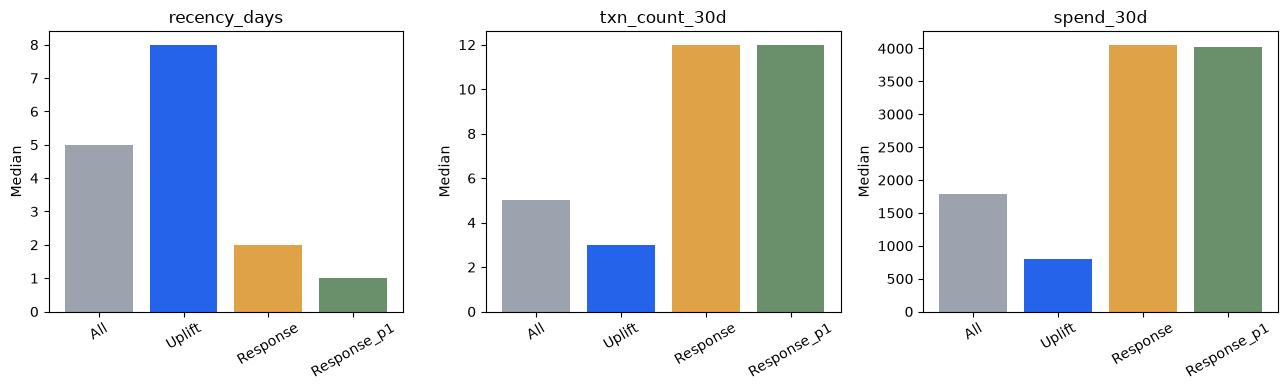

In [5]:
numeric_profile, gender_profile, overlap = customer_profiles(evaluation, policy_config)
display(numeric_profile.pivot(index="feature", columns="group", values="median").round(2))
display(gender_profile.round(3))
display(overlap.round(3))
numeric_profile.to_csv(OUT / "customer_numeric_profiles.csv", index=False)
gender_profile.to_csv(OUT / "customer_gender_profiles.csv", index=False)
overlap.to_csv(OUT / "strategy_overlap.csv", index=False)
fig, axes = plt.subplots(1, 3, figsize=(13, 4))
for ax, feature in zip(axes, ["recency_days", "txn_count_30d", "spend_30d"]):
    data = numeric_profile.loc[numeric_profile.feature.eq(feature)].set_index("group")
    ax.bar(data.index, data["median"], color=["#9ca3af", "#2563eb", "#e0a247", "#6a8f6b"])
    ax.set_title(feature); ax.set_ylabel("Median"); ax.tick_params(axis="x", rotation=30)
fig.tight_layout(); fig.savefig(FIG / "selected_customer_profiles.png", dpi=160); plt.show()

## 4. 客户 bootstrap：每次重选前 20%

以客户为单位有放回重抽验证集。重复抽中的客户以多个副本保留；每次重新按既定分数选择前 20%，并在同一份重抽样本上计算策略差异。随机策略仍为同名额随机触达的期望收益，不额外模拟随机名单噪声。

模型、处理概率假设和训练得到的 RFM 阈值保持固定。报告 500 次重抽的逐项百分位区间，适用于独立客户及适当的分位截点正则条件下的近似检查；不是同时区间，也不包含重新训练、未观测混杂及分析选择的不确定性。大量同分及截点附近离散性可能影响区间近似，需结合后面的重复划分检查。

,kind,comparison,estimate_per_1000,ci_low,ci_high,repeats,seed,interval
0,gain,RFM,2.809,0.509,5.367,500,20261113,percentile_customer_bootstrap_fixed_models
1,gain,Response,2.779,0.632,5.462,500,20261113,percentile_customer_bootstrap_fixed_models
2,gain,Response_p1,3.824,1.362,6.249,500,20261113,percentile_customer_bootstrap_fixed_models
3,gain,Uplift,10.734,6.556,14.793,500,20261113,percentile_customer_bootstrap_fixed_models
4,gain,Random,6.384,4.751,8.070,500,20261113,percentile_customer_bootstrap_fixed_models
5,paired_difference,Uplift - RFM,7.925,3.037,12.452,500,20261113,percentile_customer_bootstrap_fixed_models
6,paired_difference,Uplift - Response,7.955,2.985,12.296,500,20261113,percentile_customer_bootstrap_fixed_models
7,paired_difference,Uplift - Response_p1,6.910,2.263,11.327,500,20261113,percentile_customer_bootstrap_fixed_models
8,paired_difference,Uplift - Random,4.350,0.806,7.811,500,20261113,percentile_customer_bootstrap_fixed_models


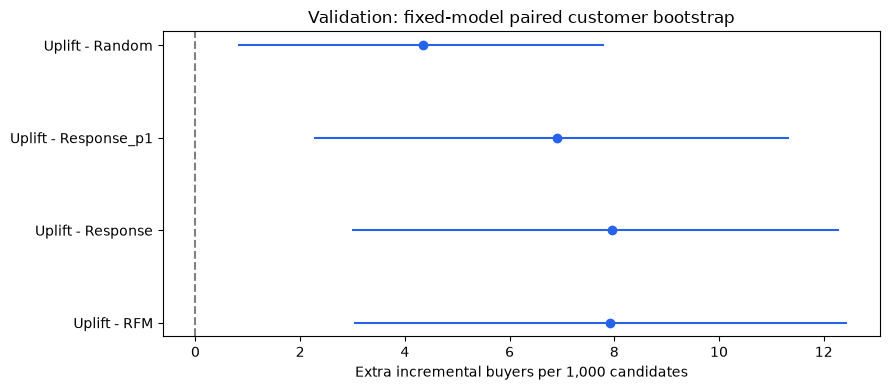

In [6]:
bootstrap_results = bootstrap_policies(evaluation, policy_config, BOOTSTRAP_REPEATS, BOOTSTRAP_SEED)
display(bootstrap_results.round(3))
bootstrap_results.to_csv(OUT / "customer_bootstrap_results.csv", index=False)
fig, ax = plt.subplots(figsize=(9, 4))
plot = bootstrap_results.loc[bootstrap_results.kind.eq("paired_difference")].reset_index(drop=True)
# Percentile intervals need not contain the point estimate; draw endpoints directly.
ax.hlines(range(len(plot)), plot.ci_low, plot.ci_high, color="#2563eb")
ax.scatter(plot.estimate_per_1000, range(len(plot)), color="#2563eb")
ax.axvline(0, color="gray", linestyle="--")
ax.set_yticks(range(len(plot)), plot.comparison)
ax.set_xlabel("Extra incremental buyers per 1,000 candidates")
ax.set_title("Validation: fixed-model paired customer bootstrap")
fig.tight_layout(); fig.savefig(FIG / "bootstrap_strategy_differences.png", dpi=160); plt.show()

## 5. 五次开发集划分的稳定性检查

合并原训练集与验证集，按处理标记分层，以固定种子 101、202、303、404、505 分别重新划分。每次只在本次训练部分拟合预处理、Response、m0、m1 和 RFM 阈值，在对应留出部分评价；分类器随机种子仍固定为 42，以观察训练样本变化的影响。

保留原训练／验证文件，不修改原测试客户。不同划分存在客户重叠，因此汇总均值、标准差、范围和点估计为正的次数仅为描述统计，不除以根号 5 构造区间，不把五次结果当成独立实验，也不挑选最好一次。

,comparison,extra_gain_per_1000,ci_low,ci_high,split_seed,method,fit_customers,evaluation_customers
0,Uplift - Response,13.355,8.587,18.123,101,DR,120023,40008
1,Uplift - Response_p1,14.007,9.249,18.765,101,DR,120023,40008
2,Uplift - Random,8.453,4.814,12.093,101,DR,120023,40008
3,Uplift - RFM,13.549,8.706,18.392,101,DR,120023,40008
4,Uplift - Response,8.998,-1.449,19.446,101,IPW,120023,40008
5,Uplift - Response_p1,8.848,-1.531,19.227,101,IPW,120023,40008
6,Uplift - Random,6.198,0.408,11.989,101,IPW,120023,40008
7,Uplift - RFM,8.498,-1.818,18.814,101,IPW,120023,40008
8,Uplift - Response,10.359,5.610,15.108,202,DR,120023,40008
9,Uplift - Response_p1,10.266,5.533,14.998,202,DR,120023,40008


,method,comparison,repetitions,descriptive_mean,descriptive_sd,minimum,maximum,positive_point_estimates
0,DR,Uplift - RFM,5,9.183,3.546,3.691,13.549,5
1,DR,Uplift - Random,5,5.480,2.025,3.253,8.453,5
2,DR,Uplift - Response,5,9.368,2.851,5.539,13.355,5
3,DR,Uplift - Response_p1,5,9.474,3.070,5.595,14.007,5
4,IPW,Uplift - RFM,5,6.139,5.742,0.000,14.297,4
5,IPW,Uplift - Random,5,4.455,2.986,1.049,7.558,5
6,IPW,Uplift - Response,5,5.759,4.464,0.050,9.348,5
7,IPW,Uplift - Response_p1,5,6.079,5.147,-1.500,11.348,4


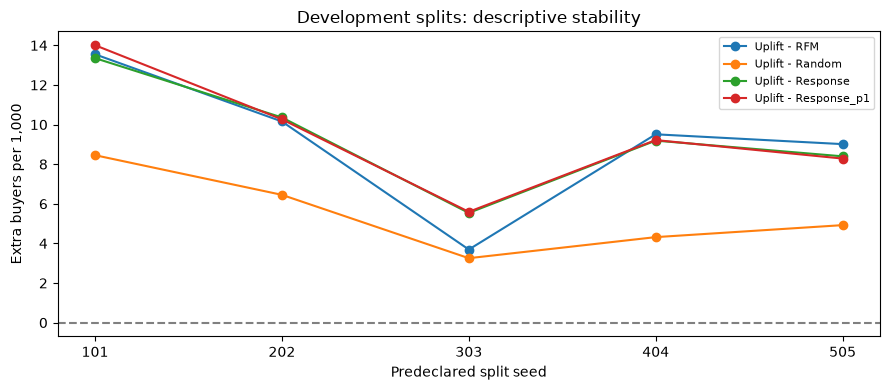

In [7]:
stability_details, stability_summary = repeated_split_stability(
    train_df, valid_df, test_df, model_config, policy_config, seeds=SPLIT_SEEDS)
display(stability_details.round(3))
display(stability_summary.round(3))
stability_details.to_csv(OUT / "repeated_split_details.csv", index=False)
stability_summary.to_csv(OUT / "repeated_split_descriptive_summary.csv", index=False)
fig, ax = plt.subplots(figsize=(9, 4))
for comparison, group in stability_details.loc[stability_details.method.eq("DR")].groupby("comparison"):
    ax.plot(group.split_seed.astype(str), group.extra_gain_per_1000, marker="o", label=comparison)
ax.axhline(0, color="gray", linestyle="--")
ax.set(xlabel="Predeclared split seed", ylabel="Extra buyers per 1,000", title="Development splits: descriptive stability")
ax.legend(fontsize=8); fig.tight_layout(); fig.savefig(FIG / "split_stability.png", dpi=160); plt.show()

## 6. 成本情景与结论生成

没有实际毛利和触达成本数据，因此下面只计算“每新增购买客户平均贡献毛利为 m”时的每次触达盈亏平衡成本：`c* = 增量购买人数 / 触达人数 × m`。这是简化情景，假设毛利可按新增购买客户数线性换算，不考虑原有购买者客单价变化、退货、履约及渠道固定成本。

金额采用任意一致货币单位，不对应本数据已知的真实利润。不同策略同名额比较时，相同的单次触达成本会抵消。这里不据此选择新预算。

In [8]:
base = sensitivity_gains.loc[(sensitivity_gains.propensity_scenario == "assumed_0.5") & (sensitivity_gains.method == "DR")]
uplift_row = base.set_index("strategy").loc["Uplift"]
scenario = pd.DataFrame({"assumed_margin_per_incremental_buyer": [5., 10., 20., 50.]})
scenario["break_even_contact_cost_point"] = scenario.assumed_margin_per_incremental_buyer * uplift_row.gain_per_1000 / uplift_row.contacts_per_1000
scenario["scenario_only"] = True
display(scenario.round(4))
scenario.to_csv(OUT / "illustrative_cost_scenarios.csv", index=False)

primary = sensitivity_differences.loc[sensitivity_differences.comparison.eq("Uplift - Response")]
dr_primary = primary.loc[primary.method.eq("DR")]
stab_primary = stability_summary.loc[(stability_summary.method == "DR") & (stability_summary.comparison == "Uplift - Response")].iloc[0]
s_compare = s_differences.loc[s_differences.comparison.eq("Uplift - Slearner")].set_index("method")
boot_primary = bootstrap_results.loc[bootstrap_results.comparison.eq("Uplift - Response")].iloc[0]
overlap_primary = overlap.loc[overlap.comparison.eq("Uplift vs Response")].iloc[0]
lines = ["# 新增探索分析运行摘要", "",
    "结果由本次运行生成；原测试集未参与新增评价。", "",
    f"处理概率三种设定下，DR 的 Uplift − Response 点估计范围：{dr_primary.extra_gain_per_1000.min():.2f} 至 {dr_primary.extra_gain_per_1000.max():.2f} 人／千名候选客户。",
    f"验证集逻辑回归处理概率 AUC：{propensity_diagnostics.auc.iloc[0]:.4f}；截断比例：{propensity_diagnostics.clipped_fraction.iloc[0]:.4%}。",
    f"五次开发划分中，主比较 DR 点估计为正 {int(stab_primary.positive_point_estimates)} 次；范围 {stab_primary.minimum:.2f} 至 {stab_primary.maximum:.2f} 人／千人。",
    f"验证集主比较 DR 点估计为 {boot_primary.estimate_per_1000:.2f} 人／千人；500 次重新选人 bootstrap 的近似 95% 区间为 [{boot_primary.ci_low:.2f}, {boot_primary.ci_high:.2f}]。",
    f"验证集 Uplift 与 Response 各选 {int(overlap_primary.selected_each):,} 人，名单重合率为 {overlap_primary.overlap_share:.2%}。",
    "", "## S-learner 对照（完整报告）", "",
    "差异定义为 T-learner 排序策略减去 S-learner 排序策略，负值表示 S-learner 点估计更高。单位均为每千名候选客户的新增购买人数。",
    "", "| 估计方法 | T − S | 近似 95% 区间 |", "|---|---:|---|",
    *[f"| {method} | {s_compare.loc[method, 'extra_gain_per_1000']:.2f} | [{s_compare.loc[method, 'ci_low']:.2f}, {s_compare.loc[method, 'ci_high']:.2f}] |" for method in ["DR", "IPW"]],
    "", "两种评价均报告，不用其中一种替代另一种。单个探索性对照及未经多重校正的区间不支持宣布某个模型普遍最优，也不据此改选原主模型。",
    "", "## 解读规则", "",
    "- 点估计方向、区间和训练样本稳定性分别报告；不要自动写成显著且稳健。",
    "- 处理概率敏感性不能排除未观测混杂；bootstrap 不包含模型重新训练的不确定性。",
    "- S-learner 对照、客户画像、重复划分及成本情景均为探索分析。",
    "- 各次划分并非独立实验，不对其均值做普通 t 检验。",
    "- 成本表是简化假设情景，不是已实现利润。",
    "- 最终主张应结合 reports/audit 下全部表格，不得仅挑选有利结果。"]
(OUT / "summary.md").write_text("\n".join(lines), encoding="utf-8")
manifest.update(status="completed", completed_utc=datetime.now(timezone.utc).isoformat(),
    output_sha256={str(p): sha256(p) for p in sorted(OUT.glob("*.csv"))})
(OUT / "run_metadata.json").write_text(json.dumps(manifest, ensure_ascii=False, indent=2), encoding="utf-8")
display(Markdown("\n".join(lines)))

,assumed_margin_per_incremental_buyer,break_even_contact_cost_point,scenario_only
0,5.0,0.2683,True
1,10.0,0.5367,True
2,20.0,1.0733,True
3,50.0,2.6833,True


# 新增探索分析运行摘要

结果由本次运行生成；原测试集未参与新增评价。

处理概率三种设定下，DR 的 Uplift − Response 点估计范围：7.96 至 8.01 人／千名候选客户。
验证集逻辑回归处理概率 AUC：0.4996；截断比例：0.0000%。
五次开发划分中，主比较 DR 点估计为正 5 次；范围 5.54 至 13.36 人／千人。
验证集主比较 DR 点估计为 7.96 人／千人；500 次重新选人 bootstrap 的近似 95% 区间为 [2.98, 12.30]。
验证集 Uplift 与 Response 各选 8,002 人，名单重合率为 1.00%。

## S-learner 对照（完整报告）

差异定义为 T-learner 排序策略减去 S-learner 排序策略，负值表示 S-learner 点估计更高。单位均为每千名候选客户的新增购买人数。

| 估计方法 | T − S | 近似 95% 区间 |
|---|---:|---|
| DR | -1.98 | [-5.60, 1.63] |
| IPW | -6.00 | [-11.63, -0.37] |

两种评价均报告，不用其中一种替代另一种。单个探索性对照及未经多重校正的区间不支持宣布某个模型普遍最优，也不据此改选原主模型。

## 解读规则

- 点估计方向、区间和训练样本稳定性分别报告；不要自动写成显著且稳健。
- 处理概率敏感性不能排除未观测混杂；bootstrap 不包含模型重新训练的不确定性。
- S-learner 对照、客户画像、重复划分及成本情景均为探索分析。
- 各次划分并非独立实验，不对其均值做普通 t 检验。
- 成本表是简化假设情景，不是已实现利润。
- 最终主张应结合 reports/audit 下全部表格，不得仅挑选有利结果。